# Per-compound error bars and a confidence score

[11_continuous.ipynb](11_continuous.ipynb) gave every model one error bar: the replicate noise density widened by a single model-error $\tau$, chosen on validation. That bar is honest on average — 90% of held-out votes fall inside the 90% interval — but it is the same width for every compound, and the learned splits showed the model's error is concentrated, not uniform. A bar that is narrow where the model is good and wide where it is bad is more useful, and it also scores higher: the information score rewards a density for being right about its own width.

This notebook does that for the best model, the random forest on the 152 descriptors, using a handle the forest gives for free: the **spread of its 500 trees' predictions** for a compound. Compounds the trees disagree on are compounds the training data describe poorly. On each split's validation side, compounds are cut into five quantile bins of spread and $(\tau, \varepsilon)$ is calibrated per bin; the test side is scored with those per-bin values and, for comparison, with the single $(\tau, \varepsilon)$ of the previous notebook. Coverage is checked per bin.

The second half turns the predictive density into a **confidence score** in $[0, 1]$. For a compound whose predictive density is $q$, the information the prediction is expected to carry, if it is calibrated, is $h(Y) - h(q)$: how much narrower than the dataset's own distribution of solubility the prediction is. Dividing by the floor $h(Y) - h(e)$ gives

$$c(x) = \frac{h(Y) - h(q_x)}{h(Y) - h(e)}$$

clipped to $[0, 1]$: **0** means the prediction is no narrower than quoting the dataset's distribution, the "random" baseline; **1** means the only uncertainty left is the measurement's own noise — a perfect replica of the universe could do no better, because a measurement of it would still scatter by $e$. It needs no label, so it can be quoted with a prediction. Because it is an expectation, it has a check: averaged over a population it should match the information actually realized there, and where it does not, the model is overconfident.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import RandomForestRegressor

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from aqsoldb_harness import GRID, Noise, calibrate_c, corrected_se, differential_entropy, entropy_c, noise_residuals  # noqa: E402

measurements = pd.read_csv(ROOT / "data" / "aqsoldb_measurements.csv")
values = measurements[~measurements["flagged"]].reset_index(drop=True)
splits = pd.read_csv(ROOT / "data" / "aqsoldb_splits.csv", index_col="InChIKey")
learned = pd.read_csv(ROOT / "data" / "aqsoldb_splits_ls.csv", index_col="InChIKey").reindex(splits.index)
features = pd.read_csv(ROOT / "data" / "aqsoldb_features.csv", index_col="InChIKey").reindex(splits.index)
CV_SPLITS = [c for c in splits.columns if c.startswith("cv_") and c[3:].isdigit()]
CLUSTER_SPLITS = [c for c in splits.columns if c.startswith("cluster_") and c[8:].isdigit()]
LS_SPLITS = [c for c in learned.columns if c.startswith("ls_") and c[3:].isdigit()]
SCHEMES = {"random cross-validation": CV_SPLITS, "cluster cross-validation": CLUSTER_SPLITS, "learning to split": LS_SPLITS}
all_splits = splits.join(learned[LS_SPLITS])

compound = splits.index.get_indexer(values["InChIKey"])
assert (compound >= 0).all()
y = values["Solubility"].to_numpy()
n_compounds = len(splits)
votes_per = np.bincount(compound, minlength=n_compounds)
w = 1 / votes_per[compound]
X = features.to_numpy()

noise = Noise(noise_residuals(measurements))
H_ALL = entropy_c(y, w)  # h(Y) over every unflagged vote: the "random" baseline is quoting this distribution
FLOOR = H_ALL - noise.entropy
marginal = stats.gaussian_kde(y, weights=w)(GRID)  # the dataset's own distribution of logS, for per-vote realized information


def sides(split: str):
    side = all_splits[split].to_numpy()
    return side == "train", side == "validation", side == "test"


def test_to_train(split_list):
    return (all_splits[split_list[0]] == "test").sum() / (all_splits[split_list[0]] == "train").sum()


def confidence(tau: float, eps: float) -> float:
    return float(np.clip((H_ALL - differential_entropy(noise.predictive(tau, eps))) / FLOOR, 0, 1))


print(f"{len(values)} votes, {n_compounds} compounds; h(Y) = {H_ALL:.3f}, h(e) = {noise.entropy:.3f}, floor = {FLOOR:.3f} bits")

12013 votes, 9946 compounds; h(Y) = 3.248, h(e) = 1.824, floor = 1.424 bits


## Calibrating τ per spread bin

`RF_SETTINGS` are the features notebook's. For each split: fit, take every tree's prediction for every compound, keep the mean (the forest's prediction) and the standard deviation across trees (the spread). Bin edges are the validation side's spread quantiles; the same edges bin the test side. Per bin, $(\tau, \varepsilon)$ is the pair with the lowest cross-entropy on the validation votes in that bin. The uniform calibration is the previous notebook's: one pair on all validation votes.

In [2]:
RF_SETTINGS = dict(n_estimators=500, n_jobs=-1, random_state=0)
K = 5  # spread bins; our choice. ponytail: a step function in spread; a smooth τ(spread) map if the steps look coarse
LEVELS = {"inside 50% (%)": 0.5, "inside 90% (%)": 0.9}


def fit(train):
    rows = train[compound]
    model = RandomForestRegressor(**RF_SETTINGS).fit(X[compound[rows]], y[rows], sample_weight=w[rows])
    trees = np.stack([t.predict(X) for t in model.estimators_])
    return trees.mean(axis=0), trees.std(axis=0)


def log2_density(err, taus, epss):
    out = np.empty(len(err))
    for t, e in set(zip(taus, epss)):
        m = (taus == t) & (epss == e)
        out[m] = noise.log2_density(err[m], t, e)
    return out


def inside(err, taus, epss, level):
    out = np.empty(len(err), bool)
    for t, e in set(zip(taus, epss)):
        m = (taus == t) & (epss == e)
        out[m] = np.abs(err[m]) <= noise.interval(t, e, level)
    return out


started = time.time()
records = []
for scheme, split_list in SCHEMES.items():
    for split in split_list:
        train, validation, test = sides(split)
        prediction, spread = fit(train)
        err = y - prediction[compound]
        v, t = validation[compound], test[compound]
        edges = np.quantile(spread[validation], np.linspace(0, 1, K + 1)[1:-1])
        bin_of = np.searchsorted(edges, spread)  # per compound
        uniform = calibrate_c(y[v], prediction[compound[v]], w[v], noise)
        per_bin = {}
        for b in range(K):
            m = v & (bin_of[compound] == b)
            per_bin[b] = calibrate_c(y[m], prediction[compound[m]], w[m], noise)
        tb = bin_of[compound[t]]
        taus, epss = np.array([per_bin[b][0] for b in tb]), np.array([per_bin[b][1] for b in tb])
        tu, eu = np.full(t.sum(), uniform[0]), np.full(t.sum(), uniform[1])
        records.append(pd.DataFrame({
            "scheme": scheme, "split": split, "compound": compound[t], "y": y[t], "w": w[t], "prediction": prediction[compound[t]],
            "spread": spread[compound[t]], "bin": tb, "τ": taus, "ε": epss, "τ uniform": uniform[0], "ε uniform": uniform[1],
            "log2 q": log2_density(err[t], taus, epss), "log2 q uniform": log2_density(err[t], tu, eu),
            "log2 marginal": np.log2(np.interp(y[t], GRID, marginal)),
            **{f"{name}": inside(err[t], taus, epss, level) for name, level in LEVELS.items()},
            **{f"{name} uniform": inside(err[t], tu, eu, level) for name, level in LEVELS.items()},
        }))
    print(f"{scheme}: {(time.time() - started) / 60:.0f} min")
rows = pd.concat(records, ignore_index=True)
rows["confidence"] = [confidence(t, e) for t, e in zip(rows["τ"], rows["ε"])]
rows["confidence uniform"] = [confidence(t, e) for t, e in zip(rows["τ uniform"], rows["ε uniform"])]
rows["90% half-width"] = [noise.interval(t, e, 0.9) for t, e in zip(rows["τ"], rows["ε"])]


def wmean(d, col):
    return (d["w"] * d[col]).sum() / d["w"].sum()


def summarize(d):
    # information uses h(Y) of the whole population, so bins and schemes are on one scale
    return pd.Series({
        "information (bits)": H_ALL + wmean(d, "log2 q"), "information, uniform τ (bits)": H_ALL + wmean(d, "log2 q uniform"),
        "inside 50% (%)": 100 * wmean(d, "inside 50% (%)"), "inside 90% (%)": 100 * wmean(d, "inside 90% (%)"),
        "inside 50%, uniform (%)": 100 * wmean(d, "inside 50% (%) uniform"), "inside 90%, uniform (%)": 100 * wmean(d, "inside 90% (%) uniform"),
        "expected confidence": wmean(d, "confidence"), "realized share of floor": (H_ALL + wmean(d, "log2 q")) / FLOOR,
    })


per_split = rows.groupby(["scheme", "split"], sort=False).apply(summarize, include_groups=False)
blocks = {}
for scheme, split_list in SCHEMES.items():
    d = per_split.loc[scheme]
    se = d.std() if scheme == "learning to split" else d.apply(corrected_se, n_splits=len(split_list), test_to_train=test_to_train(split_list))
    blocks[scheme] = d.mean().round(3).astype(str) + " ± " + se.round(3).astype(str)
pd.DataFrame(blocks).T

random cross-validation: 3 min


cluster cross-validation: 6 min


learning to split: 7 min


,information (bits),"information, uniform τ (bits)",inside 50% (%),inside 90% (%),"inside 50%, uniform (%)","inside 90%, uniform (%)",expected confidence,realized share of floor
random cross-validation,1.374 ± 0.025,1.247 ± 0.028,55.69 ± 1.12,93.983 ± 0.582,50.683 ± 0.764,90.056 ± 1.08,0.782 ± 0.012,0.965 ± 0.017
cluster cross-validation,1.288 ± 0.019,1.151 ± 0.018,53.791 ± 1.046,93.39 ± 0.382,50.509 ± 1.368,89.935 ± 0.903,0.75 ± 0.013,0.904 ± 0.013
learning to split,0.065 ± 0.041,-0.334 ± 0.154,24.731 ± 1.602,73.218 ± 1.238,19.331 ± 0.934,64.874 ± 0.892,0.79 ± 0.025,0.046 ± 0.029


## Inside the bins

Random cross-validation, test rows pooled over the ten splits. Bin 0 is the fifth of compounds the trees agree on most; bin 4 the fifth they disagree on most. For each bin: the spread range, the calibrated $(\tau, \varepsilon)$ (median over splits), the 90% half-width of the resulting bar, the RMSE of the point prediction, the coverage of the per-bin bars and of the uniform bar, the realized information as a share of the floor, and the confidence score the bin's bar implies.

In [3]:
def bin_table(scheme):
    d = rows[rows["scheme"] == scheme]
    out = []
    for b, g in d.groupby("bin"):
        err = g["y"] - g["prediction"]
        out.append({
            "spread (logS)": f"{g['spread'].min():.2f}–{g['spread'].max():.2f}", "τ (logS)": g["τ"].median(), "ε": g["ε"].median(),
            "90% half-width (logS)": g["90% half-width"].median(), "RMSE (logS)": float(np.sqrt((g["w"] * err**2).sum() / g["w"].sum())),
            "inside 50% (%)": 100 * wmean(g, "inside 50% (%)"), "inside 90% (%)": 100 * wmean(g, "inside 90% (%)"),
            "inside 90%, uniform (%)": 100 * wmean(g, "inside 90% (%) uniform"),
            "realized share of floor": (H_ALL + wmean(g, "log2 q")) / FLOOR, "realized, uniform τ": (H_ALL + wmean(g, "log2 q uniform")) / FLOOR,
            "confidence": wmean(g, "confidence"),
        })
    return pd.DataFrame(out, index=pd.Index(range(K), name="spread bin")).round(2)


display(bin_table("random cross-validation"))
display(bin_table("cluster cross-validation").rename_axis("spread bin (cluster splits)"))
bin_table("learning to split").rename_axis("spread bin (learned splits)")

,spread (logS),τ (logS),ε,90% half-width (logS),RMSE (logS),inside 50% (%),inside 90% (%),"inside 90%, uniform (%)",realized share of floor,"realized, uniform τ",confidence
spread bin,,,,,,,,,,,
0,0.12–0.68,0.0,0.0,1.48,0.50,74.88,98.88,99.08,1.51,1.43,1.00
1,0.64–0.86,0.0,0.0,1.48,0.69,55.73,96.03,97.29,1.24,1.22,1.00
2,0.83–1.09,0.3,0.0,1.56,0.84,49.21,93.76,95.02,1.04,1.03,0.91
3,1.03–1.40,0.6,0.0,1.79,1.06,49.67,91.95,89.98,0.80,0.77,0.74
4,1.33–3.53,1.5,0.1,3.04,1.83,49.33,89.33,68.86,0.23,-0.07,0.25


,spread (logS),τ (logS),ε,90% half-width (logS),RMSE (logS),inside 50% (%),inside 90% (%),"inside 90%, uniform (%)",realized share of floor,"realized, uniform τ",confidence
spread bin (cluster splits),,,,,,,,,,,
0,0.14–0.78,0.0,0.0,1.48,0.56,68.64,98.05,98.74,1.44,1.33,1.00
1,0.61–0.96,0.0,0.0,1.48,0.72,52.16,96.07,98.08,1.19,1.16,0.99
2,0.86–1.18,0.4,0.0,1.62,0.91,49.83,93.19,94.59,0.96,0.94,0.84
3,1.07–1.45,0.7,0.0,1.89,1.14,49.27,90.37,89.36,0.72,0.69,0.70
4,1.31–3.76,1.5,0.2,3.04,1.86,48.84,89.23,69.02,0.21,-0.08,0.23


,spread (logS),τ (logS),ε,90% half-width (logS),RMSE (logS),inside 50% (%),inside 90% (%),"inside 90%, uniform (%)",realized share of floor,"realized, uniform τ",confidence
spread bin (learned splits),,,,,,,,,,,
0,0.18–0.55,0.0,0.0,1.48,1.13,31.15,88.98,89.13,0.66,0.66,1.00
1,0.51–0.69,0.0,0.0,1.48,1.21,22.11,83.21,83.58,0.43,0.45,1.00
2,0.66–0.85,0.0,0.0,1.48,1.35,22.74,74.13,74.28,0.27,0.27,1.00
3,0.82–1.14,0.4,0.0,1.62,1.69,23.68,67.70,64.05,0.01,-0.12,0.88
4,1.08–4.03,1.0,0.1,2.52,2.63,26.16,67.48,43.86,-0.42,-1.22,0.44


## Is the floor itself a landscape?

In the lowest-spread bins the forest realizes more than the pooled floor with $\tau = 0$: the votes land closer to its predictions than the pooled noise density says a measurement can. That is only possible if those compounds' measurements are quieter than average. The check uses the replicate residuals the floor was built from (compounds with 3+ unflagged votes), grouped by the compound's out-of-fold spread from the random splits: per bin, the robust SD of the residuals, the noise entropy from a KDE on that bin alone, and the floor it implies. The bins are coarse — about 55 compounds each — so read the trend, not the decimals.

In [4]:
by_key = {k: g["Solubility"].to_numpy() for k, g in measurements[~measurements["flagged"]].groupby("InChIKey")}
spread_of = pd.Series(rows[rows["scheme"] == "random cross-validation"].groupby("compound", sort=True)["spread"].first().to_numpy(), index=splits.index)  # out-of-fold
edges_all = np.quantile(spread_of, np.linspace(0, 1, K + 1)[1:-1])
residuals = pd.DataFrame(
    [(k, (g[i] - np.delete(g, i).mean()) * np.sqrt((len(g) - 1) / len(g))) for k, g in by_key.items() if len(g) >= 3 for i in range(len(g))],
    columns=["InChIKey", "residual"],
)
residuals["bin"] = np.searchsorted(edges_all, spread_of.loc[residuals["InChIKey"]].to_numpy())
landscape = []
for b, g in residuals.groupby("bin"):
    nb_ = Noise(g["residual"].to_numpy())
    landscape.append({"compounds": g["InChIKey"].nunique(), "residuals": len(g), "robust noise SD (logS)": 1.4826 * float(np.median(np.abs(g["residual"]))),
                      "h(e) (bits)": nb_.entropy, "floor (bits)": H_ALL - nb_.entropy, "90% half-width, noise alone (logS)": nb_.interval(0, 0, 0.9)})
landscape = pd.DataFrame(landscape, index=pd.Index(range(K), name="spread bin"))
landscape.loc["pooled"] = [residuals["InChIKey"].nunique(), len(residuals), 1.4826 * float(np.median(np.abs(residuals["residual"]))), noise.entropy, FLOOR, noise.interval(0, 0, 0.9)]
landscape.round(2)

,compounds,residuals,robust noise SD (logS),h(e) (bits),floor (bits),"90% half-width, noise alone (logS)"
spread bin,,,,,,
0,59.0,187.0,0.49,1.26,1.99,0.92
1,55.0,179.0,0.46,1.23,2.02,0.92
2,53.0,172.0,0.53,1.84,1.41,1.61
3,56.0,196.0,0.77,2.16,1.09,1.93
4,101.0,401.0,0.70,2.15,1.10,1.90
pooled,324.0,1135.0,0.59,1.82,1.42,1.48


## Confidence: model level and compound level

The model-level score is the same formula with the uniform $(\tau, \varepsilon)$ each model chose in the continuous notebook (medians over the random splits, read from its error-bar table), beside the information each actually realized there as a share of the floor. A calibrated model's two numbers agree. The compound-level score is the forest's per-bin one, drawn as a distribution over the out-of-fold predictions of the random splits.

In [5]:
MODEL_LEVEL = {  # (τ, ε) medians and realized information on random splits, all test compounds, from 11_continuous.ipynb
    "Delaney's equation (published)": (0.8, 0.20, 0.270), "least squares refit of ESOL's form": (1.2, 0.10, 0.373),
    "EBM, main effects, ESOL (4)": (0.8, 0.10, 0.836), "EBM, 5 pairs, ESOL (4)": (0.6, 0.10, 0.915), "random forest, ESOL (4)": (0.5, 0.15, 0.935),
    "EBM, main effects, RDKit, one per group (152)": (0.4, 0.05, 1.191), "EBM, 20 pairs, RDKit, one per group (152)": (0.35, 0.05, 1.213),
    "random forest, RDKit, one per group (152)": (0.3, 0.05, 1.283),
}
model_level = pd.DataFrame(
    {"τ (logS)": {m: t for m, (t, e, i) in MODEL_LEVEL.items()}, "ε": {m: e for m, (t, e, i) in MODEL_LEVEL.items()},
     "confidence (expected)": {m: confidence(t, e) for m, (t, e, i) in MODEL_LEVEL.items()},
     "realized share of floor": {m: i / FLOOR for m, (t, e, i) in MODEL_LEVEL.items()}}
)
model_level.loc["random forest, 152, per-compound bars"] = [np.nan, np.nan, per_split.loc["random cross-validation", "expected confidence"].mean(), per_split.loc["random cross-validation", "realized share of floor"].mean()]
model_level.round(2)

,τ (logS),ε,confidence (expected),realized share of floor
Delaney's equation (published),0.80,0.20,0.43,0.19
least squares refit of ESOL's form,1.20,0.10,0.34,0.26
"EBM, main effects, ESOL (4)",0.80,0.10,0.52,0.59
"EBM, 5 pairs, ESOL (4)",0.60,0.10,0.62,0.64
"random forest, ESOL (4)",0.50,0.15,0.61,0.66
"EBM, main effects, RDKit, one per group (152)",0.40,0.05,0.79,0.84
"EBM, 20 pairs, RDKit, one per group (152)",0.35,0.05,0.81,0.85
"random forest, RDKit, one per group (152)",0.30,0.05,0.83,0.90
"random forest, 152, per-compound bars",NaN,NaN,0.78,0.96


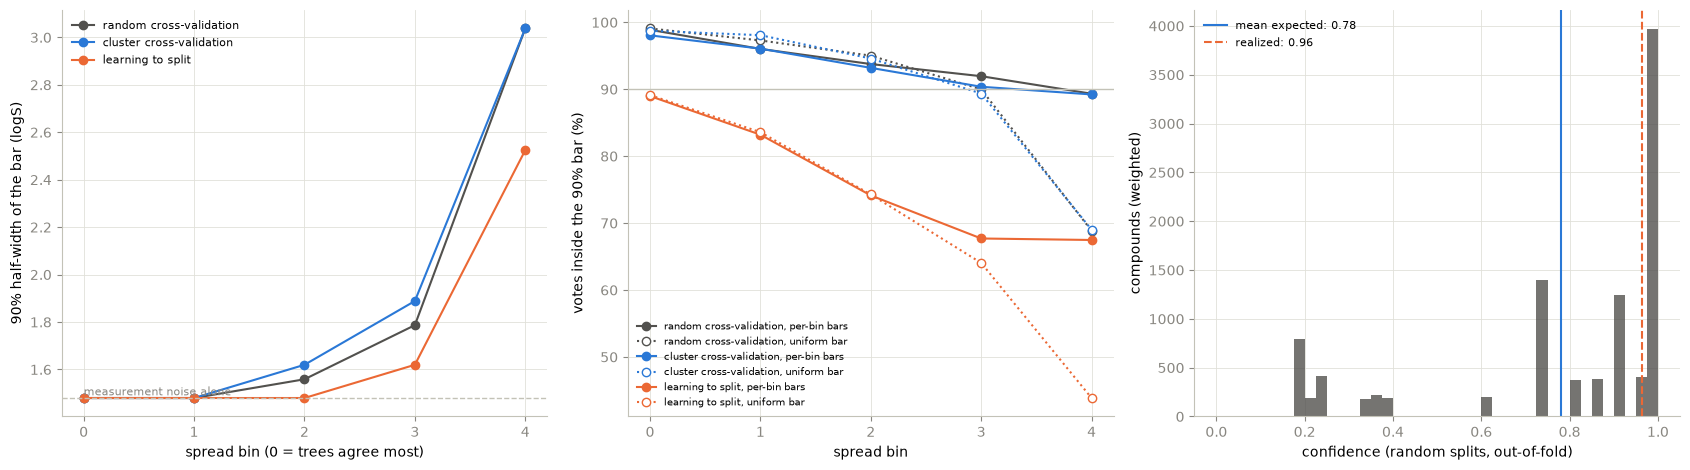

In [6]:
INK, MUTED, GRID_C, AXIS = "#52514e", "#898781", "#e1e0d9", "#c3c2b7"


def style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(AXIS)
    ax.tick_params(colors=MUTED)
    ax.grid(color=GRID_C, lw=0.6)
    ax.set_axisbelow(True)


random_cv = rows[rows["scheme"] == "random cross-validation"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

ax = axes[0]
for scheme, color in zip(SCHEMES, ["#52514e", "#2a78d6", "#eb6834"]):
    d = rows[rows["scheme"] == scheme].groupby("bin")["90% half-width"].median()
    ax.plot(d.index, d.to_numpy(), "o-", color=color, label=scheme)
ax.axhline(noise.interval(0, 0, 0.9), color=AXIS, lw=1, ls="--")
ax.text(0, noise.interval(0, 0, 0.9), "measurement noise alone", color=MUTED, fontsize=8, va="bottom")
ax.set_xlabel("spread bin (0 = trees agree most)")
ax.set_ylabel("90% half-width of the bar (logS)")
ax.set_xticks(range(K))
ax.legend(frameon=False, fontsize=8)
style(ax)

ax = axes[1]
for scheme, color in zip(SCHEMES, ["#52514e", "#2a78d6", "#eb6834"]):
    d = rows[rows["scheme"] == scheme].groupby("bin").apply(lambda g: 100 * wmean(g, "inside 90% (%)"), include_groups=False)
    u = rows[rows["scheme"] == scheme].groupby("bin").apply(lambda g: 100 * wmean(g, "inside 90% (%) uniform"), include_groups=False)
    ax.plot(d.index, d.to_numpy(), "o-", color=color, label=f"{scheme}, per-bin bars")
    ax.plot(u.index, u.to_numpy(), "o:", color=color, mfc="white", label=f"{scheme}, uniform bar")
ax.axhline(90, color=AXIS, lw=1)
ax.set_xlabel("spread bin")
ax.set_ylabel("votes inside the 90% bar (%)")
ax.set_xticks(range(K))
ax.legend(frameon=False, fontsize=7)
style(ax)

ax = axes[2]
ax.hist(random_cv["confidence"], bins=np.linspace(0, 1, 41), weights=random_cv["w"], color=INK, alpha=0.8)
ax.axvline(wmean(random_cv, "confidence"), color="#2a78d6", lw=1.5, label=f"mean expected: {wmean(random_cv, 'confidence'):.2f}")
ax.axvline((H_ALL + wmean(random_cv, "log2 q")) / FLOOR, color="#eb6834", lw=1.5, ls="--", label=f"realized: {(H_ALL + wmean(random_cv, 'log2 q')) / FLOOR:.2f}")
ax.set_xlabel("confidence (random splits, out-of-fold)")
ax.set_ylabel("compounds (weighted)")
ax.legend(frameon=False, fontsize=8)
style(ax)
fig.tight_layout()

## Hand-off: one prediction per compound

Every compound is on the test side of exactly one random split, so the random splits give one out-of-fold prediction per compound. Written with its spread, bar and confidence, beside the consensus of its measurements.

In [7]:
by_compound = random_cv.groupby("compound", sort=True)
assert (by_compound["split"].nunique() == 1).all() and len(by_compound) == n_compounds, "each compound should be tested in exactly one random split"
consensus = measurements.groupby("InChIKey")["consensus"].first().reindex(splits.index)
predictions = pd.DataFrame({
    "InChIKey": splits.index,
    "predicted logS": by_compound["prediction"].first().to_numpy(),
    "tree spread (logS)": by_compound["spread"].first().to_numpy(),
    "τ (logS)": by_compound["τ"].first().to_numpy(),
    "ε": by_compound["ε"].first().to_numpy(),
    "90% half-width (logS)": by_compound["90% half-width"].first().to_numpy(),
    "confidence": by_compound["confidence"].first().to_numpy(),
    "consensus logS": consensus.to_numpy(),
    "unflagged votes": votes_per,
})
predictions.to_csv(ROOT / "data" / "aqsoldb_predictions.csv", index=False)
print(f"{len(predictions)} compounds -> data/aqsoldb_predictions.csv")
predictions.describe().round(2)

9946 compounds -> data/aqsoldb_predictions.csv


,predicted logS,tree spread (logS),τ (logS),ε,90% half-width (logS),confidence,consensus logS,unflagged votes
count,9946.00,9946.00,9946.00,9946.00,9946.00,9946.00,9946.00,9946.00
mean,-2.90,1.04,0.46,0.02,1.85,0.78,-2.89,1.21
std,2.09,0.49,0.53,0.06,0.56,0.28,2.38,0.58
min,-11.56,0.12,0.00,0.00,1.48,0.18,-13.17,1.00
25%,-4.13,0.71,0.00,0.00,1.48,0.74,-4.31,1.00
50%,-2.58,0.95,0.30,0.00,1.56,0.92,-2.61,1.00
75%,-1.43,1.26,0.60,0.00,1.79,1.00,-1.20,1.00
max,1.23,3.53,1.50,0.20,3.15,1.00,2.14,13.00


## Reading

1. **Per-compound bars are worth more than a better model.** Letting $\tau$ follow the trees' spread lifts the forest from 1.25 to 1.37 bits on random splits (90% to 96% of the floor) and from 1.15 to 1.29 on cluster splits. That 0.13-bit gain is twice the gap between the additive model and the forest on the continuous front, and it costs nothing: the spread is a by-product of the forest. The bars it produces are ±1.48 logS at 90% for the easiest two-fifths of compounds — measurement noise alone — then ±1.56, ±1.79, and ±3.0 for the hardest fifth, where the point prediction's RMSE is 1.8 logS. Coverage holds per bin on random and cluster splits, with one exception: the two easiest bins over-cover (96–99% inside the 90% bar) because $\tau$ cannot go below zero.

2. **That exception is the floor being a landscape.** The replicate residuals of the compounds in the two lowest-spread bins have a robust SD near 0.47 logS and imply a floor near 2.0 bits; the two highest bins have 0.70–0.77 and about 1.1 bits. Some of what the trees disagree about is the measurement itself. Two consequences. The pooled floor undervalues the easy compounds, which is why the forest realizes 1.5× the pooled floor in bin 0 and why its mean expected confidence (0.78) sits below the share it realizes (0.96). And the upgrade is clear: a noise density per spread bin, in both the predictive density and the normalizer. With ~55 replicated compounds per bin it is not done here; the pooled version is the conservative choice.

3. **Where spread does not see the error.** On the learned splits the per-bin bars raise the information from −0.33 to 0.07 bits and the 90% coverage from 65% to 73%, but the three lowest-spread bins still have RMSE 1.1–1.35 logS at $\tau = 0$. These are compounds whose training neighbours agree and are wrong for them: the model is confidently mistaken where its evidence is consistent and misleading, not where it is scarce. Spread catches scarcity; it cannot catch that. The repeat benchmark on the same compounds (0.97 bits) says a good share of them are also where measurements disagree, so part of this is label trouble rather than chemistry.

4. **The confidence score.** Model level: the forest on the 152 descriptors expects 0.83 and realizes 0.90; Delaney's equation expects 0.43 and realizes 0.19, the one clearly overconfident entry, because a single $\tau$ cannot describe an error that is small for most compounds and enormous for some. Compound level, for the forest: a median of 0.92, a quarter of compounds below 0.74, and the hardest fifth near 0.25. The scale reads as declared — 0 is quoting the dataset's distribution of solubility, 1 is a prediction a measurement could not improve on — with the caveat from point 2 that, normalized by the pooled floor, 1 means "as good as a typical measurement", not "as good as a measurement of this compound". `data/aqsoldb_predictions.csv` carries all of it, one row per compound.